## Week 2 Activity: Data Import, Export, and Exploratory Data Analysis (EDA)
### Assignment Instructions

Instructions for myself:
Do initially in python
Translate python code into R

### Objectives:
    Learn how to import and export data using R.
    Perform exploratory data analysis (EDA) using summary statistics and visualizations.
    Gain insights into patterns and trends in the dataset.

### Instructions
1. Dataset Preparation:  
    - Download the provided dataset:  
        - employee_data_week2.csv  
    - Use the read.csv() function to load the dataset into R.  
    - Display the first few rows using the head() function and check its structure using the str() function.  

2. Data Exploration:  
    - Compute the following summary statistics for the Salary and Experience variables:  
        - Mean, Median, Variance, Standard Deviation, Minimum and Maximum (Range)  

3. Visualizations:  
    - Create a histogram for the Salary variable.  
    - Create a scatterplot to visualize the relationship between Salary and Experience.  

4. Data Export:  
    - Save the modified dataset with an additional column, Salary_Category, categorizing salaries as "Low," "Medium," or "High" based on quartiles.  

5. Reflection: Write a brief reflection (200–300 words) addressing the following:  
    - What patterns or trends did you observe in the Salary and Experience data?  
    - How do the visualizations enhance your understanding of the dataset?  
    - What challenges did you encounter during the activity, and how did you address them?  

6. Deliverables, in 1 PDF combine:  
    - A well-commented R script with the completed code.  
    - The modified dataset (employee_data_modified.csv) with the new Salary_Category column.  
    - A reflection summarizing insights and observations.  

    By midnight (EST) on the last day of Week 02, click on the Assignment link at the top of this section to submit your work  

### 1. Dataset preparation

In [8]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# read dataset file
fname =  Path("../datasets/employee_data_week2.csv")

employee_data = pd.read_csv(fname)

display(employee_data.head())

# inspect the dataset
display(employee_data.describe(include="all"))

display(employee_data.info())

,EmployeeID,Age,Department,Salary,Experience,Education_Level
0,2001,49,Finance,107369,6.5,Bachelors
1,2002,59,Marketing,92998,33.5,Bachelors
2,2003,47,Finance,95451,14.5,Bachelors
3,2004,64,Sales,99967,34.1,Bachelors
4,2005,50,Finance,119921,33.1,Bachelors


,EmployeeID,Age,Department,Salary,Experience,Education_Level
count,100.000000,100.000000,100,100.000000,100.000000,100
unique,NaN,NaN,5,NaN,NaN,4
top,NaN,NaN,Sales,NaN,NaN,Bachelors
freq,NaN,NaN,22,NaN,NaN,56
mean,2050.500000,43.460000,NaN,80060.110000,20.423000,NaN
std,29.011492,11.549122,NaN,22436.184794,11.319054,NaN
min,2001.000000,24.000000,NaN,41754.000000,1.100000,NaN
25%,2025.750000,33.750000,NaN,61196.000000,12.225000,NaN
50%,2050.500000,43.000000,NaN,77795.500000,20.200000,NaN
75%,2075.250000,53.000000,NaN,100079.500000,30.425000,NaN


<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   EmployeeID       100 non-null    int64  
 1   Age              100 non-null    int64  
 2   Department       100 non-null    str    
 3   Salary           100 non-null    int64  
 4   Experience       100 non-null    float64
 5   Education_Level  100 non-null    str    
dtypes: float64(1), int64(3), str(2)
memory usage: 4.8 KB


None

### 2. Data Exploration

In [9]:
# stats for the salary and experience variables

required_variables = ["Salary", "Experience"]

print("\n--- Summary Stats ---")
func = ["mean", "median", "var", "std", "min", "max"]
stats = employee_data[required_variables].agg(func=func)
stats.loc["Range"] = stats.loc["max"] - stats.loc["min"]

display(stats.style.format({
    "Salary": "${:,.2f}",
    "Experience": "{:.2f}"
}))


--- Summary Stats ---


,Salary,Experience
mean,"$80,060.11",20.42
median,"$77,795.50",20.20
var,"$503,382,388.12",128.12
std,"$22,436.18",11.32
min,"$41,754.00",1.10
max,"$119,921.00",39.80
Range,"$78,167.00",38.70


#### 3. Visualizations
Create a histogram for the Salary variable.  
Create a scatterplot to visualize the relationship between Salary and Experience.


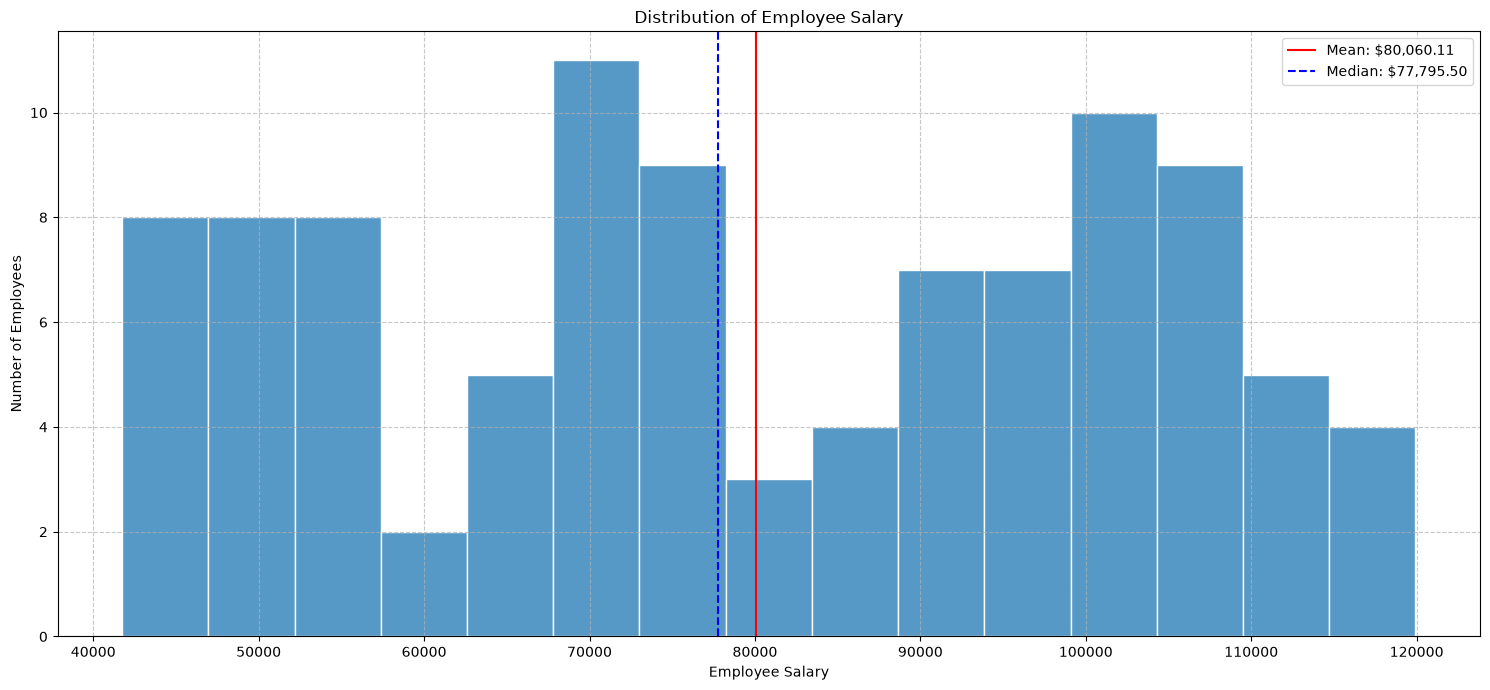

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(15, 7))

# salary histogram
sns.histplot(data=employee_data, x="Salary", bins=15, stat="count", edgecolor="white", ax=ax)
ax.set(
    title="Distribution of Employee Salary",
    xlabel="Employee Salary",
    ylabel="Number of Employees"
)

ax.grid(visible=True, axis="both", linestyle="--", alpha=0.7)

mean_salary = employee_data["Salary"].mean()
median_salary = employee_data["Salary"].median()

plt.axvline(x=mean_salary, linestyle="-", color="red", label=f"Mean: ${mean_salary:,.2f}")
plt.axvline(x=median_salary, linestyle="--", color="blue", label=f"Median: ${median_salary:,.2f}")

plt.legend()

plt.tight_layout()

[Text(0.5, 1.0, 'Scatterplot of salary vs. experience'),
 Text(0.5, 0, 'Employee Salary'),
 Text(0, 0.5, 'Experience in years')]

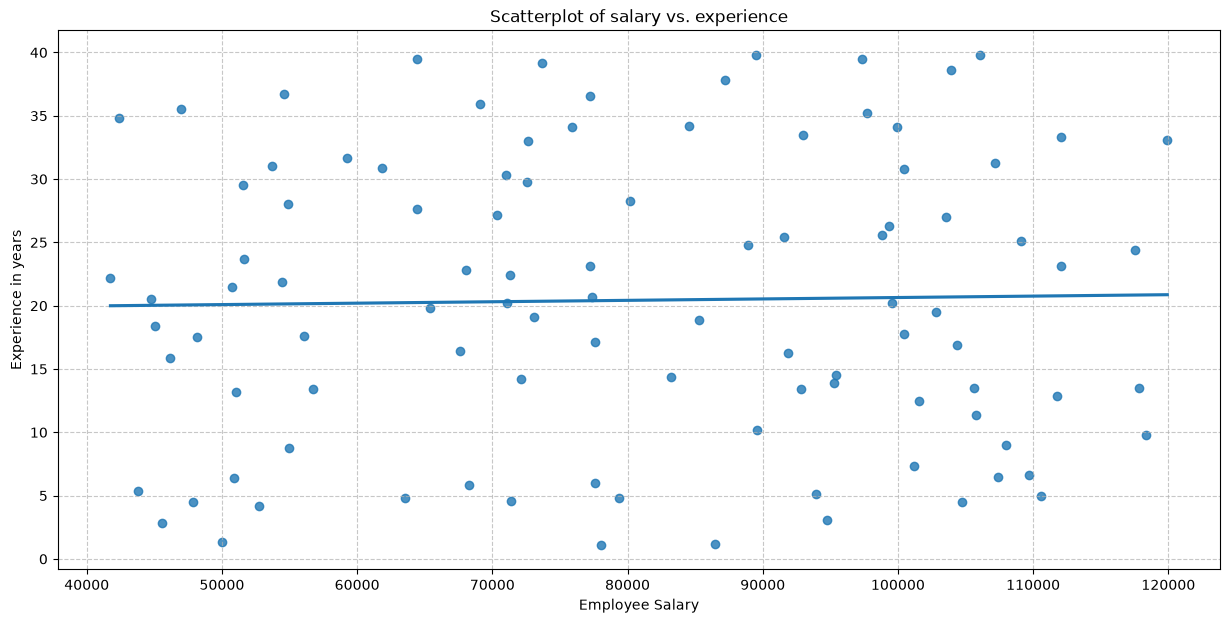

In [11]:
fig, ax = plt.subplots(1, 1, figsize=(15, 7))

# salary vs. experience scatterplot
# sns.scatterplot(data=employee_data, x="Salary", y="Experience", hue="Department", ax=ax)

ax.grid(visible=True, axis="both", linestyle="--", alpha=0.7)

# draw regression lines
sns.regplot(
    data=employee_data,
    x="Salary",
    y="Experience",
    scatter=True,
    ci=None,
    ax=ax,
    label=f"overall trend"
)

ax.set(
    title="Scatterplot of salary vs. experience",
    xlabel="Employee Salary",
    ylabel="Experience in years",
)

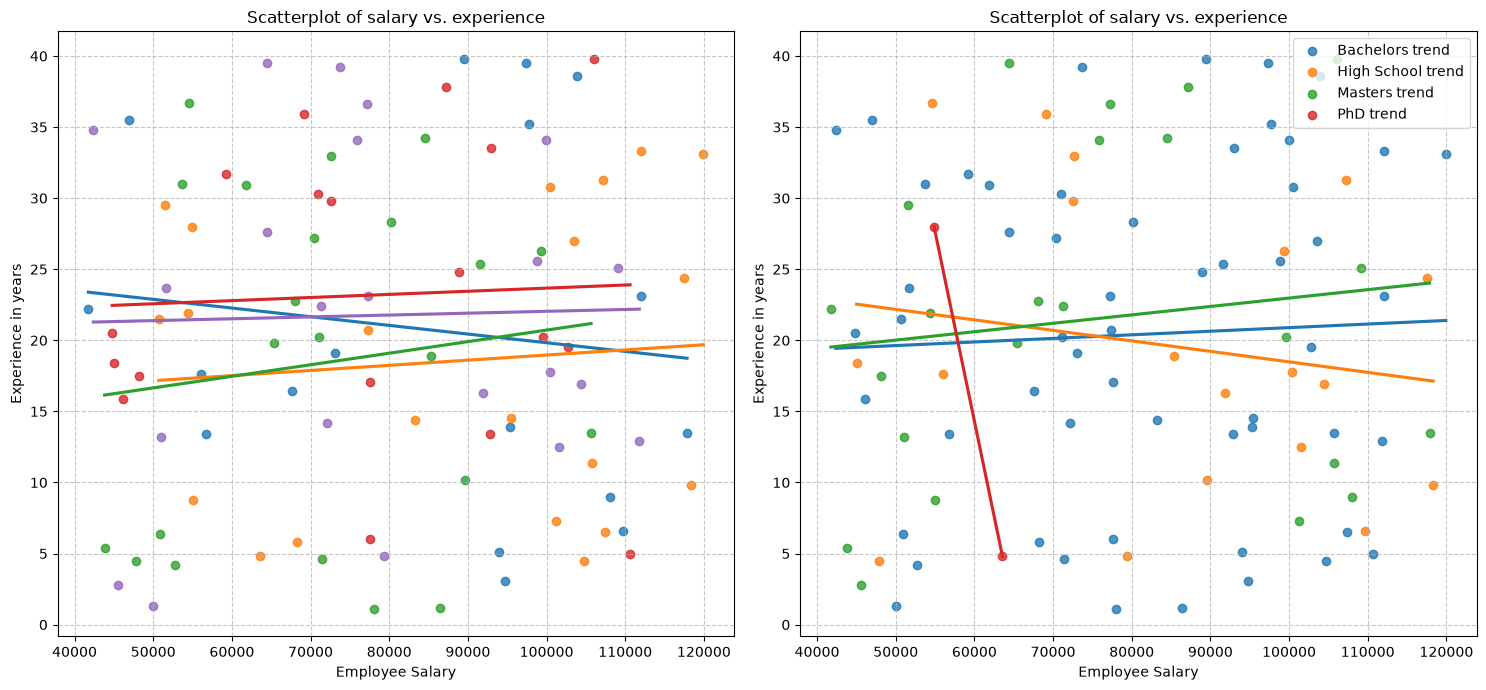

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 7))

# salary vs. experience scatterplot
# sns.scatterplot(data=employee_data, x="Salary", y="Experience", hue="Department", ax=ax)

ax[0].grid(visible=True, axis="both", linestyle="--", alpha=0.7)

# draw regression lines
for department, group in employee_data.groupby("Department"):
    sns.regplot(
        data=group,
        x="Salary",
        y="Experience",
        scatter=True,
        ci=None,
        ax=ax[0],
        label=f"{department} trend"
    )

ax[0].set(
    title="Scatterplot of salary vs. experience",
    xlabel="Employee Salary",
    ylabel="Experience in years",
)


ax[1].grid(visible=True, axis="both", linestyle="--", alpha=0.7)

# draw regression lines
for education_level, group in employee_data.groupby("Education_Level"):
    sns.regplot(
        data=group,
        x="Salary",
        y="Experience",
        scatter=True,
        ci=None,
        ax=ax[1],
        label=f"{education_level} trend"
    )

ax[1].set(
    title="Scatterplot of salary vs. experience",
    xlabel="Employee Salary",
    ylabel="Experience in years",
)

plt.legend()

plt.tight_layout()

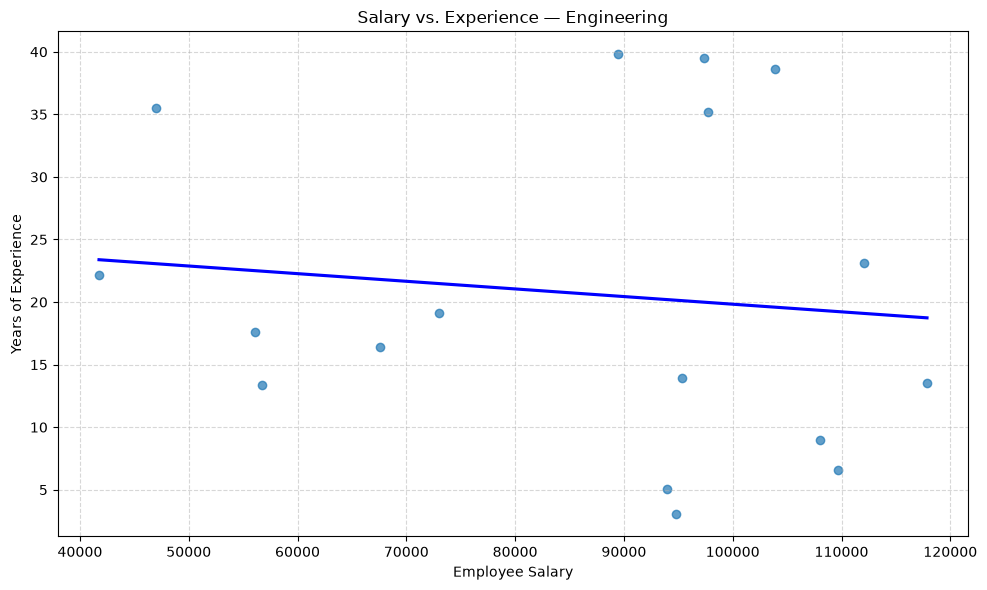

In [13]:
# scatter plot for engineering department
# salary vs. experience

engineering = employee_data[employee_data["Department"] == "Engineering"]

fig, ax = plt.subplots(figsize=(10, 6))

sns.regplot(
    data=engineering,
    x="Salary",
    y="Experience",
    ax=ax,
    ci=None,
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "blue"},
)

ax.set(
    title="Salary vs. Experience — Engineering",
    xlabel="Employee Salary",
    ylabel="Years of Experience",
)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 4. Data Export:

In [14]:
# Salary Category
# Save the modified dataset with an additional column, Salary_Category, 
# categorizing salaries as "Low," "Medium," or "High" based on tertiles.

employee_data["Salary_Category"] = pd.qcut(employee_data["Salary"], q=3, labels=["Low", "Medium", "High"])

display(employee_data.head(10))

# save the modified dataset
modified_path =  Path("../datasets/employee_data_week2_modified.csv")
employee_data.to_csv(path_or_buf=modified_path, index=False)

print("\nSuccess: Exported modified data to 'employee_data_modified.csv'")

,EmployeeID,Age,Department,Salary,Experience,Education_Level,Salary_Category
0,2001,49,Finance,107369,6.5,Bachelors,High
1,2002,59,Marketing,92998,33.5,Bachelors,Medium
2,2003,47,Finance,95451,14.5,Bachelors,High
3,2004,64,Sales,99967,34.1,Bachelors,High
4,2005,50,Finance,119921,33.1,Bachelors,High
5,2006,37,HR,61850,30.9,Bachelors,Low
6,2007,59,Engineering,56070,17.6,High School,Low
7,2008,50,HR,71078,20.2,Bachelors,Medium
8,2009,61,HR,99318,26.3,High School,High
9,2010,39,Sales,42384,34.8,Bachelors,Low



Success: Exported modified data to 'employee_data_modified.csv'


### 5. Reflection

The data set contains 100 employees and 6 variables inclusing the EmployeeID identifier, and the age, salary, experience numerical variables, as well as categorical ones, namely, Department and Education_Level.  

In this activity, I explored the relationship between employee salary and years of experience. the scatterplot shows salaries vary considerably among employees with similar experience, so experience alone does not appear to explain salary differences and it does not establish a causality relationship. The fitted regression lines shows the overall trend that salary increases as experience increases, yet that varies considerably when investigated within departments or different education levels.  

The visualizations made it easier to notice patterns that are less obvious from looking at rows of data or summary statistics alone. The histogram shows how salaries are distributed in the dataset, and it does not appear to follow a normal distribution overall. The scatterplot displays the relationship between salary and experience while the histogram focuses on the distribution of salaries.

It's a basic activiy and a good refresher working on visualization and exploring a dataset, but to understand the data further, it's worth investigating other variables that could explain the salary trends like the education level effect on salary or department vs. salary